# LGMMA-X | Phase 5G — Notebook 01

## Verified comparative analysis and Chapter IV condition figures

> **Status:** Verified frozen-inference analysis. This is a corrected research copy, not a training notebook.

**Workflow:** Frozen hashes → alignment → metrics → Figures IV-2/IV-3 → Tables IV-10–IV-13 → aligned exports

**Source safety:** No autoencoder training, GMM refitting, or rewriting of archived checkpoints. The notebooks deliberately stop when artifacts are missing or inconsistent.

---

**November 23 replay:** uses `20261123T024650` and writes only to `reproduction/phase5g_final_results_20261123/`. Frozen source integrity checks remain active. These are candidates until baseline provenance checks and notebook execution pass.


### 1. Imports and repository configuration

Locate the repository automatically from its root or `notebooks/` directory. All generated files are written under `reproduction/phase5g_final_results/`.

In [1]:
import sys
print(sys.executable)
print("Jupyter kernel connected successfully!")

c:\Users\Kyle Eva\Downloads\datasci2-thesis\.venv\Scripts\python.exe
Jupyter kernel connected successfully!


In [2]:
from pathlib import Path

import hashlib, json

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, average_precision_score

def repo_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / 'src/modeling/data/evaluation/test_proxy_labels.csv').exists() and (candidate / 'reproduction').is_dir():
            return candidate.resolve()
    raise FileNotFoundError('Run from the thesis repository or its notebooks/ subdirectory')

ROOT = repo_root()

OUT = ROOT / 'reproduction/phase5g_final_results_20261123'

OUT.mkdir(parents=True, exist_ok=True)

REPLAY = ROOT / 'reproduction/verified_dag_runs/20261123T024650/replay'

LABELS = ROOT / 'src/modeling/data/evaluation/test_proxy_labels.csv'

META = ROOT / 'src/modeling/data/sequence_metadata/test_sequence_metadata.parquet'

HELDOUT = ROOT / 'reproduction/heldout_evaluation/reproduced_test_scores.csv'

THRESHOLD = ROOT / 'reproduction/gmm_calibration/selected_threshold.txt'

EXPECTED = {LABELS: '0c71225d0d4af73599c23555e6d093987ac459ed74b19ff78e8b40d51e422f8c', META: '508f830b4056f1f0084dc1fec594651dda0293dd7af017116907b779a580a7ad', REPLAY / 'test_predictions.npy': 'cea82f3bf6d5e5312871e960bde4b5ac69e62d23a5bc83ea83ff97f8e59a8f68', REPLAY / 'test_anomaly_scores.npy': '38d087fd00ceb37547899886817ccecec3a257f793a718ae24e6bb89191ec460', REPLAY / 'test_reconstruction_errors.npy': '6184101ff0a55d259c6082543f1a875806a504363ef0980bc433e6c371f50177', THRESHOLD: '532dd182b3253f13af4a9743b391c734991db58969f67ea27d6b94d63ce04270'}


### 2. Frozen-artifact integrity gate

Compare source files against their known SHA-256 digests. A mismatch stops execution before any analysis.

In [3]:
def digest(p):
    h = hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

for path, known in EXPECTED.items():
    if not path.is_file():
        raise FileNotFoundError(str(path))
    actual = digest(path)
    if actual != known:
        raise ValueError(f'Frozen artifact changed: {path}\n{actual} != {known}')

print('[PASS] 7 frozen input hashes. Root:', ROOT)


[PASS] 7 frozen input hashes. Root: C:\Users\Kyle Eva\Downloads\datasci2-thesis


### 3. Sequence and inference alignment

Verify sequence IDs, segments, timestamps, proxy criteria, scores, labels, and predictions against the held-out evaluation.

In [4]:
labels = pd.read_csv(LABELS).sort_values('sequence_id').reset_index(drop=True)

meta = pd.read_parquet(META).sort_values('sequence_id').reset_index(drop=True)

ids = labels.sequence_id.to_numpy(dtype=int)

if not (len(ids) == 21749 and np.array_equal(ids, np.arange(21749))):
    raise ValueError('Sequence IDs are not 0..21748')

if not np.array_equal(meta.sequence_id.to_numpy(), ids):
    raise ValueError('Metadata ID mismatch')

if not np.array_equal(meta.segment_id.to_numpy(), labels.segment_id.to_numpy()):
    raise ValueError('Segment ID mismatch')

for key in ('start_timestamp', 'end_timestamp'):
    a = pd.to_datetime(meta[key], utc=True).to_numpy()
    b = pd.to_datetime(labels[key], utc=True).to_numpy()
    if not np.array_equal(a, b):
        raise ValueError(f'Metadata timestamp mismatch: {key}')

y = labels.proxy_anomaly.to_numpy(dtype=np.int8)

criteria = ['extreme_return', 'range_expansion', 'volatility_burst', 'flash_movement']

if not np.array_equal(y, (labels[criteria].to_numpy().sum(axis=1) > 0).astype(np.int8)):
    raise ValueError('Proxy labels do not match OR of criteria')

scores = np.load(REPLAY / 'test_anomaly_scores.npy', allow_pickle=False)

pred = np.load(REPLAY / 'test_predictions.npy', allow_pickle=False)

mae = np.load(REPLAY / 'test_reconstruction_errors.npy', allow_pickle=False)

cutoff = float(THRESHOLD.read_text().strip())

if any((len(a) != 21749 for a in (scores, pred, mae))):
    raise ValueError('Output length mismatch')

if not np.array_equal(pred, (scores >= cutoff).astype(np.int8)):
    raise ValueError('GMM threshold mismatch')

prior = pd.read_csv(HELDOUT).sort_values('sequence_id').reset_index(drop=True)

if not np.array_equal(prior.sequence_id.to_numpy(), ids):
    raise ValueError('Heldout sequence ID mismatch')

if not np.array_equal(prior.proxy_anomaly.to_numpy(), y):
    raise ValueError('Heldout label mismatch')

if not np.array_equal(prior.predicted_anomaly.to_numpy(), pred):
    raise ValueError('Heldout prediction mismatch')

if not np.allclose(prior.anomaly_score.to_numpy(), scores, atol=1e-10, rtol=0):
    raise ValueError('Heldout score mismatch')

if not np.allclose(prior.reconstruction_error.to_numpy(), mae, atol=1e-06, rtol=0):
    raise ValueError('Heldout MAE mismatch')

assert tuple(confusion_matrix(y, pred, labels=[0, 1]).ravel()) == (3422, 498, 3713, 14116)

base = labels[['sequence_id', 'segment_id', 'start_timestamp', 'end_timestamp', 'proxy_anomaly']].copy()

base['start_timestamp'] = pd.to_datetime(base.start_timestamp, utc=True)

base['end_timestamp'] = pd.to_datetime(base.end_timestamp, utc=True)

print('[PASS] aligned 21,749 sequences; TP=14116, TN=3422, FP=498, FN=3713; threshold', cutoff)


[PASS] aligned 21,749 sequences; TP=14116, TN=3422, FP=498, FN=3713; threshold -0.27292780574931297


### 4. Metric helper

Use the same standard classification and ranking metrics throughout both notebooks.

In [5]:
def rates(true, prediction, values):
    t = true.to_numpy() if isinstance(true, pd.Series) else np.asarray(true)
    p = prediction.to_numpy() if isinstance(prediction, pd.Series) else np.asarray(prediction)
    s = values.to_numpy() if isinstance(values, pd.Series) else np.asarray(values)
    result = {'precision': precision_score(t, p, zero_division=0), 'recall': recall_score(t, p, zero_division=0), 'f1': f1_score(t, p, zero_division=0), 'balanced_accuracy': balanced_accuracy_score(t, p), 'roc_auc': roc_auc_score(t, s), 'average_precision': average_precision_score(t, s)}
    return result


## 5. Verified held-out model performance

Compute LGMMA-X classification metrics, ROC-AUC, and Average Precision from the frozen 21,749-sequence evaluation. Compare raw-MAE ranking performance.

---

In [6]:
print(pd.DataFrame([rates(y, pred, scores)]).T.rename(columns={0: 'verified_value'}).to_string())
print('MAE ROC-AUC / AP:', roc_auc_score(y, mae), average_precision_score(y, mae))


                   verified_value
precision                0.965923
recall                   0.791744
f1                       0.870203
balanced_accuracy        0.832351
roc_auc                  0.914754
average_precision        0.980911
MAE ROC-AUC / AP: 0.914757672377381 0.9809114823520715


## 6. Figures IV-2 and IV-3 — proxy-condition diagnostics

Recalculate criterion-positive detections and criterion-overlap rates from the verified labels and predictions. Save both figures and Tables IV-10 and IV-11.

---

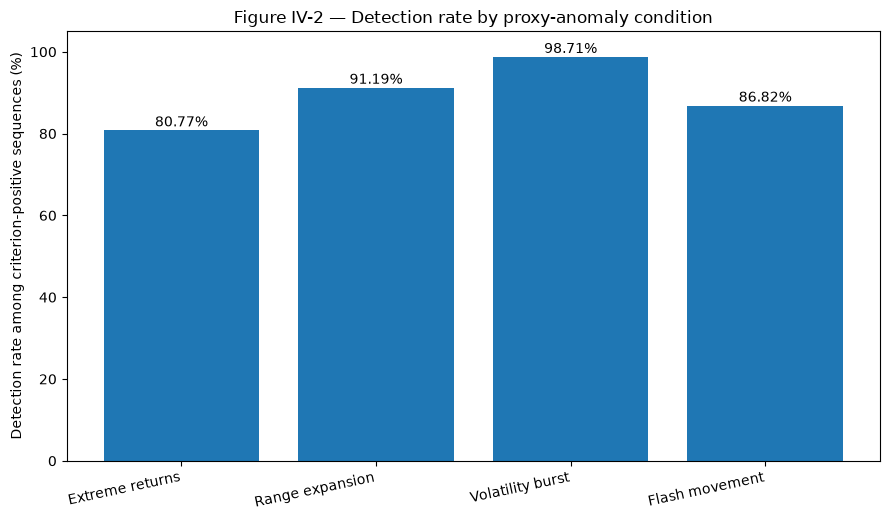

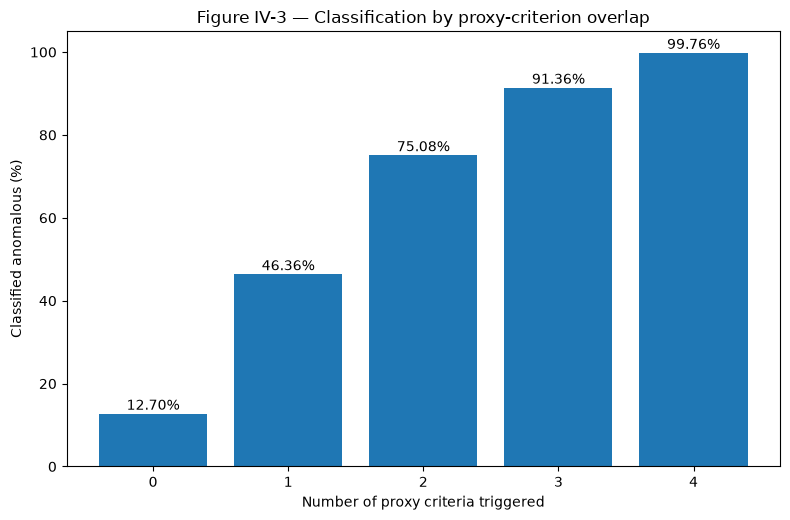

,condition,criterion_positive,detected,missed,rate_pct
0,extreme_return,16980,13714,3266,80.765607
1,range_expansion,11911,10862,1049,91.193015
2,volatility_burst,4567,4508,59,98.708123
3,flash_movement,11416,9911,1505,86.816748
4,overall_proxy_positive,17829,14116,3713,79.174379


,criteria_triggered,sequences,classified_anomalous,classified_normal,classified_anomalous_pct
0,0,3920,498,3422,12.704082
1,1,3790,1757,2033,46.358839
2,2,4827,3624,1203,75.077688
3,3,5418,4950,468,91.362126
4,4,3794,3785,9,99.762783


In [7]:
condition_names = {'extreme_return': 'Extreme returns', 'range_expansion': 'Range expansion', 'volatility_burst': 'Volatility burst', 'flash_movement': 'Flash movement'}
condition_rows = []
for field in criteria:
    mask = labels[field].to_numpy(dtype=bool)
    count = int(mask.sum())
    detected = int(pred[mask].sum())
    condition_rows.append({'condition': field, 'criterion_positive': count, 'detected': detected, 'missed': count - detected, 'rate_pct': 100 * detected / count})
condition_rows.append({'condition': 'overall_proxy_positive', 'criterion_positive': int(y.sum()), 'detected': int(pred[y == 1].sum()), 'missed': int((1 - pred[y == 1]).sum()), 'rate_pct': 100 * pred[y == 1].mean()})
condition = pd.DataFrame(condition_rows)
assert condition.set_index('condition').loc['extreme_return', 'detected'] == 13714
assert condition.set_index('condition').loc['volatility_burst', 'detected'] == 4508
condition.to_csv(OUT / 'table_IV10_condition_detection.csv', index=False)
overlap_rows = []
counts = labels[criteria].sum(axis=1).to_numpy()
for k in range(5):
    mask = counts == k
    amount = int(mask.sum())
    positives = int(pred[mask].sum())
    overlap_rows.append({'criteria_triggered': k, 'sequences': amount, 'classified_anomalous': positives, 'classified_normal': amount - positives, 'classified_anomalous_pct': 100 * positives / amount})
overlap = pd.DataFrame(overlap_rows)
assert overlap.sequences.sum() == 21749 and overlap.classified_anomalous.sum() == 14614
condition_display = condition.iloc[:4].copy()
fig, ax = plt.subplots(figsize=(9, 5.3))
ax.bar([condition_names[x] for x in condition_display.condition], condition_display.rate_pct)
ax.set_ylim(0, 105)
ax.set_ylabel('Detection rate among criterion-positive sequences (%)')
ax.set_title('Figure IV-2 — Detection rate by proxy-anomaly condition')
for i, v in enumerate(condition_display.rate_pct):
    ax.text(i, v + 1, f'{v:.2f}%', ha='center')
plt.xticks(rotation=12, ha='right')
fig.tight_layout()
fig.savefig(OUT / 'figure_IV2_condition_detection.png', dpi=220)
plt.show()
fig, ax = plt.subplots(figsize=(8, 5.3))
ax.bar(overlap.criteria_triggered.astype(str), overlap.classified_anomalous_pct)
ax.set_ylim(0, 105)
ax.set_xlabel('Number of proxy criteria triggered')
ax.set_ylabel('Classified anomalous (%)')
ax.set_title('Figure IV-3 — Classification by proxy-criterion overlap')
for i, v in enumerate(overlap.classified_anomalous_pct):
    ax.text(i, v + 1, f'{v:.2f}%', ha='center')
fig.tight_layout()
fig.savefig(OUT / 'figure_IV3_criterion_overlap.png', dpi=220)
plt.show()
overlap.to_csv(OUT / 'table_IV11_criterion_overlap.csv', index=False)
display(condition)
display(overlap)


## 7. Table IV-12 — groupwise score distributions

Calculate reconstruction-MAE and GMM-score means and sample standard deviations for proxy-normal and proxy-anomalous sequences.

---

In [8]:
rows = []
for label, value in [('proxy_normal', 0), ('proxy_anomalous', 1)]:
    mask = y == value
    rows.append({'proxy_label': label, 'sequences': int(mask.sum()), 'mae_mean': float(mae[mask].mean()), 'mae_sd_sample': float(mae[mask].std(ddof=1)), 'gmm_mean': float(scores[mask].mean()), 'gmm_sd_sample': float(scores[mask].std(ddof=1))})
summary = pd.DataFrame(rows)
summary.to_csv(OUT / 'table_IV12_group_statistics.csv', index=False)
display(summary)


,proxy_label,sequences,mae_mean,mae_sd_sample,gmm_mean,gmm_sd_sample
0,proxy_normal,3920,0.480424,0.067207,-0.568736,0.324166
1,proxy_anomalous,17829,0.751230,0.250877,1.016877,1.489452


## 8. Table IV-13 — candidate model comparison

Read the previously reconciled seven-model candidate report, gate its key metrics, and export a copy. The fixed-MAE calibration remains provisional.

---

In [9]:
RECON = ROOT / 'reproduction/phase5g_chapter4_reconciliation/table_IV13_candidate_seven_models.csv'
if not RECON.is_file():
    raise FileNotFoundError('First run phase5g_reconcile_chapter4.py from repository root')
models = pd.read_csv(RECON)
if len(models) != 7 or not models.model.str.contains('LGMMA-X').any():
    raise ValueError('Unexpected candidate Table IV-13 structure')
expected = {'Z-score', 'Isolation Forest', 'One-Class SVM', 'ARIMA-GARCH'}
if not expected.issubset(set(models.model)):
    raise ValueError('Baseline aggregate rows missing')
main = models.loc[models.model.str.contains('LGMMA-X')].iloc[0]
for k, v in [('f1', 0.8702031254816139), ('balanced_accuracy', 0.8323514859418444), ('roc_auc', 0.9147543385518434)]:
    if abs(float(main[k]) - v) > 1e-11:
        raise ValueError('Aggregate row mismatch: ' + k)
models.to_csv(OUT / 'table_IV13_candidate_seven_models.csv', index=False)
display(models[['model', 'precision', 'recall', 'f1', 'balanced_accuracy', 'roc_auc', 'average_precision', 'evidence']])
print('STATUS: CANDIDATE, not a final-release table. Fixed-MAE cutoff selection provenance unresolved.')


,model,precision,recall,f1,balanced_accuracy,roc_auc,average_precision,evidence
0,LGMMA-X (verified Exp04),0.965923,0.791744,0.870203,0.832351,0.914754,0.980911,VERIFIED_INFERENCE_REPLAY
1,Z-score,0.896675,0.927253,0.911708,0.720642,0.895374,0.975167,ARCHIVED_AGGREGATE_PLUS_PHASE5E3_SAVED_MODEL_R...
2,Isolation Forest,0.965562,0.842896,0.900069,0.853081,0.931143,0.984571,ARCHIVED_AGGREGATE_PLUS_PHASE5E3_SAVED_MODEL_R...
3,One-Class SVM,0.995326,0.656963,0.791499,0.821466,0.889026,0.975855,ARCHIVED_AGGREGATE_PLUS_PHASE5E3_SAVED_MODEL_R...
4,ARIMA-GARCH,0.979582,0.562398,0.714555,0.754541,0.832150,0.960598,PHASE5E4_SAVED_STATE_SEQUENCE_REPLAY
5,LSTM-AE (Raw Error Ranking),NaN,NaN,NaN,NaN,0.914758,0.980911,VERIFIED_EXP04_RECONSTRUCTION_ERROR_RANKING
6,LSTM-AE (Reproduction Fixed Threshold),0.965923,0.791744,0.870203,0.832351,0.914758,0.980911,CANDIDATE_THRESHOLD_FROM_REPRODUCTION_VALIDATE...


STATUS: CANDIDATE, not a final-release table. Fixed-MAE cutoff selection provenance unresolved.


## 9. Export aligned inputs for Notebook 02

Export verified GMM, ARIMA–GARCH, raw-MAE, and provisional fixed-MAE sequence-level records. Notebook 02 also requires the other three saved-state baseline replay exports.

---

In [10]:
SCORE_DIR = OUT / 'aligned_score_sources'
SCORE_DIR.mkdir(exist_ok=True)

def save_aligned(name, s, p=None):
    t = base.copy()
    t['anomaly_score'] = np.asarray(s, dtype=float)
    if p is not None:
        t['prediction'] = np.asarray(p, dtype=int)
    t.to_csv(SCORE_DIR / name, index=False)
    return t
save_aligned('lgmma_verified.csv', scores, pred)
save_aligned('lstm_raw_error_verified.csv', mae)
fixed_cutoff = float((ROOT / 'reproduction/lstm_baseline_comparison/fixed_threshold.txt').read_text().strip())
fixed_pred = (mae >= fixed_cutoff).astype(np.int8)
assert np.array_equal(fixed_pred, pred)
save_aligned('lstm_fixed_candidate.csv', mae, fixed_pred)
archive = ROOT / 'src/baseline/data/traditional/arima_garch_test_scores.csv'
arc = pd.read_csv(archive).sort_values('sequence_id').reset_index(drop=True)
assert np.array_equal(arc.sequence_id.to_numpy(), ids) and np.array_equal(arc.proxy_anomaly.to_numpy(), y)
assert np.array_equal(pd.to_datetime(arc.start_timestamp, utc=True).to_numpy(), base.start_timestamp.to_numpy())
assert np.array_equal(pd.to_datetime(arc.end_timestamp, utc=True).to_numpy(), base.end_timestamp.to_numpy())
for name, col in [('segment_id', 'segment_id')]:
    assert np.array_equal(arc[col].to_numpy(), base[col].to_numpy())
assert np.allclose(arc.anomaly_score.to_numpy(), np.load(ROOT / 'reproduction/phase5e4_arima_replay/replayed_test_sequence_scores.npy'), rtol=0, atol=1e-07)
save_aligned('arima_garch_verified.csv', arc.anomaly_score.to_numpy(), arc.prediction.to_numpy())
print('Wrote four score sources:', SCORE_DIR)
print('Still need standardized, replay-verified *per-sequence* Z-score, Isolation Forest and One-Class SVM scoring files for Notebook 02.')


Wrote four score sources: C:\Users\Kyle Eva\Downloads\datasci2-thesis\reproduction\phase5g_final_results_20261123\aligned_score_sources
Still need standardized, replay-verified *per-sequence* Z-score, Isolation Forest and One-Class SVM scoring files for Notebook 02.
